In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [9]:
import torch
import torch.nn as nn
from torchvision import models

In [7]:
#Load pretrained EfficientNet
weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)

In [11]:
#Replace the classification layer with a one with only 3 outputs
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 3)

In [12]:
# Freeze the pretrained layers
for param in model.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

In [13]:
#check
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

classifier.1.weight
classifier.1.bias


In [14]:
#I will remove this cell
#Move model to GPU
device = torch.device("cuda")
model = model.to(device)

In [15]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader


In [16]:
#Prepare image transformations
# Get the normalization values used by pretrained EfficientNet

mean = weights.transforms().mean
std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224,scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_test_transform = weights.transforms()


In [ ]:
from pathlib import Path
data_dir=Path("datasetPath")

In [18]:
#Load the three datasets
train_dataset = datasets.ImageFolder(
    data_dir / "Train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    data_dir / "Validation",
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    data_dir / "Test",
    transform=val_test_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)


Training images: 1729
Validation images: 371
Testing images: 370
Classes: ['DESTROYED', 'MAJOR', 'MINOR']
Class mapping: {'DESTROYED': 0, 'MAJOR': 1, 'MINOR': 2}


In [19]:
#dataLoaders

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)


In [20]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)


Image batch shape: torch.Size([16, 3, 224, 224])
Labels shape: torch.Size([16])
Image dtype: torch.float32


In [21]:
#calculate weights

import numpy as np

class_counts = np.bincount(train_dataset.targets)

class_weights = len(train_dataset) / (
    len(class_counts) * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)


Class counts: [722 367 640]
Class weights: tensor([0.7982, 1.5704, 0.9005], device='cuda:0')


In [22]:
#Define the loss function

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)


In [24]:
#Define the optimizer

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)


In [25]:

from sklearn.metrics import f1_score


In [26]:

def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None

    model.train(training)

    # Keep BatchNorm statistics stable for our small dataset
    for layer in model.modules():
        if isinstance(layer, nn.BatchNorm2d):
            layer.eval()

    total_loss = 0
    all_labels = []
    all_predictions = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = total_loss / len(loader.dataset)

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return epoch_loss, epoch_f1


In [27]:

EPOCHS = 20
FREEZE_EPOCHS = 3
PATIENCE = 5

best_val_f1 = 0
epochs_without_improvement = 0

history = []


In [28]:
#Train and fine-tune
import copy

for epoch in range(EPOCHS):

    # Start fine-tuning after the frozen phase
    if epoch == FREEZE_EPOCHS:

        print("\nStarting fine-tuning...")

        # Unfreeze the final EfficientNet block
        for param in model.features[-1].parameters():
            param.requires_grad = True

        # Keep the earlier layers frozen
        optimizer = torch.optim.AdamW([
        {
            "params": model.features[-1].parameters(),
            "lr": 0.00001
        },
        {
            "params": model.classifier.parameters(),
            "lr": 0.0001
        }
        ],
    weight_decay=0.0001)

    train_loss, train_f1 = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_loss, val_f1 = run_epoch(
        model, val_loader, criterion
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_f1": train_f1,
        "val_f1": val_f1
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # Save the best model based on validation Macro-F1
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())

        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": best_state,
            "classes": train_dataset.classes,
            "val_macro_f1": best_val_f1
        }, "/kaggle/working/efficientnet_best.pth")

        print("Best model saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping!")
        break

print("\nBest validation Macro-F1:", best_val_f1)


Epoch 1/20 | Train Loss: 0.3642 | Train F1: 0.8825 | Val Loss: 0.1529 | Val F1: 0.9738
Best model saved!
Epoch 2/20 | Train Loss: 0.1411 | Train F1: 0.9652 | Val Loss: 0.0981 | Val F1: 0.9769
Best model saved!
Epoch 3/20 | Train Loss: 0.1016 | Train F1: 0.9737 | Val Loss: 0.0743 | Val F1: 0.9857
Best model saved!

Starting fine-tuning...
Epoch 4/20 | Train Loss: 0.0863 | Train F1: 0.9777 | Val Loss: 0.0711 | Val F1: 0.9848
Epoch 5/20 | Train Loss: 0.0766 | Train F1: 0.9826 | Val Loss: 0.0675 | Val F1: 0.9848
Epoch 6/20 | Train Loss: 0.0775 | Train F1: 0.9793 | Val Loss: 0.0643 | Val F1: 0.9848
Epoch 7/20 | Train Loss: 0.0708 | Train F1: 0.9829 | Val Loss: 0.0612 | Val F1: 0.9848
Epoch 8/20 | Train Loss: 0.0619 | Train F1: 0.9826 | Val Loss: 0.0558 | Val F1: 0.9880
Best model saved!
Epoch 9/20 | Train Loss: 0.0616 | Train F1: 0.9848 | Val Loss: 0.0541 | Val F1: 0.9880
Epoch 10/20 | Train Loss: 0.0561 | Train F1: 0.9858 | Val Loss: 0.0513 | Val F1: 0.9880
Epoch 11/20 | Train Loss: 0.0511

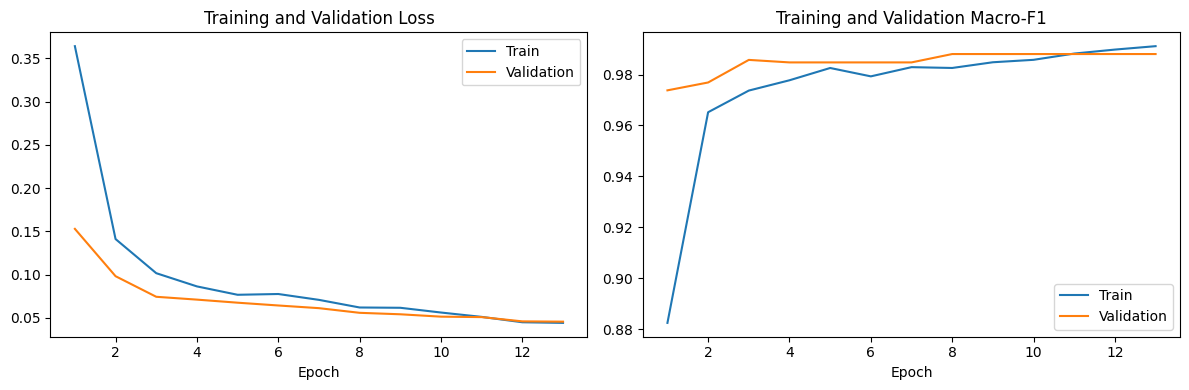

In [29]:
#Plot training curves

import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

# Macro F1
axes[1].plot(history_df["epoch"], history_df["train_f1"], label="Train")
axes[1].plot(history_df["epoch"], history_df["val_f1"], label="Validation")
axes[1].set_title("Training and Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


In [30]:
#Load the best model

checkpoint = torch.load(
    "/kaggle/working/efficientnet_best.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best validation Macro-F1:", checkpoint["val_macro_f1"])
print("Best model loaded successfully!")


Best validation Macro-F1: 0.9880442773481413
Best model loaded successfully!


In [31]:
#Final evaluation on the test set

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())


In [35]:
#Evaluation metrics
print("Test Accuracy:", accuracy_score(
    all_labels, all_predictions
))

print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes,
    digits=4
))


Test Accuracy: 0.9837837837837838

Classification Report:

              precision    recall  f1-score   support

   DESTROYED     0.9935    0.9935    0.9935       155
       MAJOR     0.9518    1.0000    0.9753        79
       MINOR     0.9924    0.9632    0.9776       136

    accuracy                         0.9838       370
   macro avg     0.9793    0.9856    0.9822       370
weighted avg     0.9842    0.9838    0.9838       370



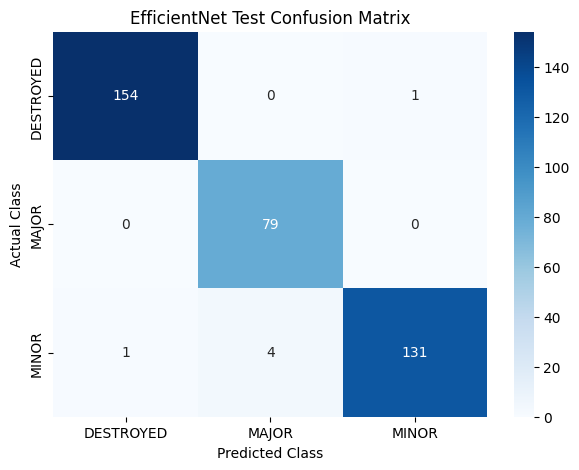

In [36]:
#Confusion Matrix

import seaborn as sns

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EfficientNet Test Confusion Matrix")

plt.show()


In [37]:

import torch
import torch.nn.functional as F

all_probabilities = []
all_confidences = []
all_predictions_conf = []

#model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        outputs = model(images)
        # Convert logits to probabilities
        probabilities = F.softmax(outputs, dim=1)

        # Get highest probability and predicted class
        confidences, predictions = probabilities.max(dim=1)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_confidences.extend(
            confidences.cpu().numpy()
        )

        all_predictions_conf.extend(
            predictions.cpu().numpy()
        )

# Convert to NumPy arrays
all_probabilities = np.array(all_probabilities)
all_confidences = np.array(all_confidences)
all_predictions_conf = np.array(all_predictions_conf)

# Display average confidence
print(
    "Average Prediction Confidence:",
    f"{all_confidences.mean():.4f}"
)


Average Prediction Confidence: 0.9591


In [38]:
# Calculate Prediction Uncertainty using Entropy

eps = 1e-12

# Calculate entropy for each image
all_entropies = -np.sum(
    all_probabilities * np.log(all_probabilities + eps),
    axis=1
)

# Normalize entropy between 0 and 1
all_uncertainties = all_entropies / np.log(len(test_dataset.classes))

# Display average uncertainty
print(
    "Average Prediction Uncertainty:",
    f"{all_uncertainties.mean():.4f}"
)


Average Prediction Uncertainty: 0.1148
